# **TEXT CLASSIFICATION FOR CLINICAL RISK SCREENING USING TF-IDF AND MACHINE LEARNING MODELS**

This study aims to develop a basic text classification system capable of analyzing short medical symptom descriptions and categorizing them into two risk levels: low risk and high risk. The proposed approach simulates the logic employed in automated clinical triage systems, which are widely used to support decision-making and prioritize patient care according to the severity of reported symptom.
<br><br>
Initially, the textual data will be transformed into numerical representations through the Term Frequency-Inverse Document Frequency (TF-IDF) method, allowing the machine learning algorithms to process linguistic information in vectoried form. Subsequently, three classification models will b implemented and compared, namely, **Decision Tree, Logistic Regression** and another classifier available from the **Scikit-learn library**.
<br><br>
The present section focuses on the first stage of model training using the Descion Tree algorithm, followed by graphical visualizatio of the results and analytical interpretation of the model performance.

In [5]:
!pip install pandas scikit-learn matplotlib seaborn

In [7]:
# Import libraries
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load dataset
df = pd.read_csv("/content/phrases_situation.csv")

# Display first rows
df.head()

,frase,situacao
0,sinto dor no peito e falta de ar,alto risco
1,tive um leve incômodo nas costas,baixo risco
2,estou com febre alta e dificuldade para respirar,alto risco
3,leve dor de cabeça desde ontem,baixo risco
4,desmaiei e estou com tontura,alto risco


In [11]:
# Convert text into numerical vectors using TF-IDF
tfidf_vectorizer = TfidfVectorizer()

x = tfidf_vectorizer.fit_transform(df["frase"])
y = df["situacao"]

print(f"TF-IDF matrix shape: {x.shape}" )

TF-IDF matrix shape: (50, 115)


### **TF-IDF Vectorization**

At this stage, the textual symptom descriptions were transformed into numerical vectos using TF-IDF (Term Frequency-Iverse Document Frequency) technique. This method assigns weights to words according to their frequency within a sentence and their relevance across the dataset, enabling the machine learning modelos to interpret textual patterns numerically.

In [12]:
#Split data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.2,
    random_state=42
)

# Create Decision Tree model
decision_tree_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train model
decision_tree_model.fit(x_train, y_train)

# Prediction
y_pred_tree = decision_tree_model.predict(x_test)

In [13]:
# Accuracy
accuracy_tree = accuracy_score(y_test, y_pred_tree)

print("Decision Tree Accuracy:", accuracy_tree)

# Classification report
print("\nClassifcation Report:\n")
print(classification_report(y_test, y_pred_tree))

Decision Tree Accuracy: 0.9

Classifcation Report:

              precision    recall  f1-score   support

  alto risco       0.80      1.00      0.89         4
 baixo risco       1.00      0.83      0.91         6

    accuracy                           0.90        10
   macro avg       0.90      0.92      0.90        10
weighted avg       0.92      0.90      0.90        10



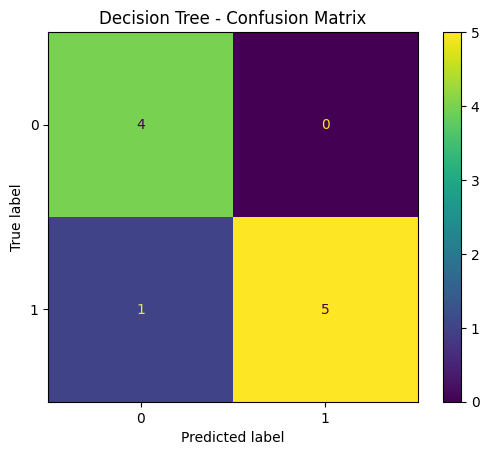

In [15]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred_tree)

# Plot confusion matrix
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()

plt.title("Decision Tree - Confusion Matrix")
plt.show()

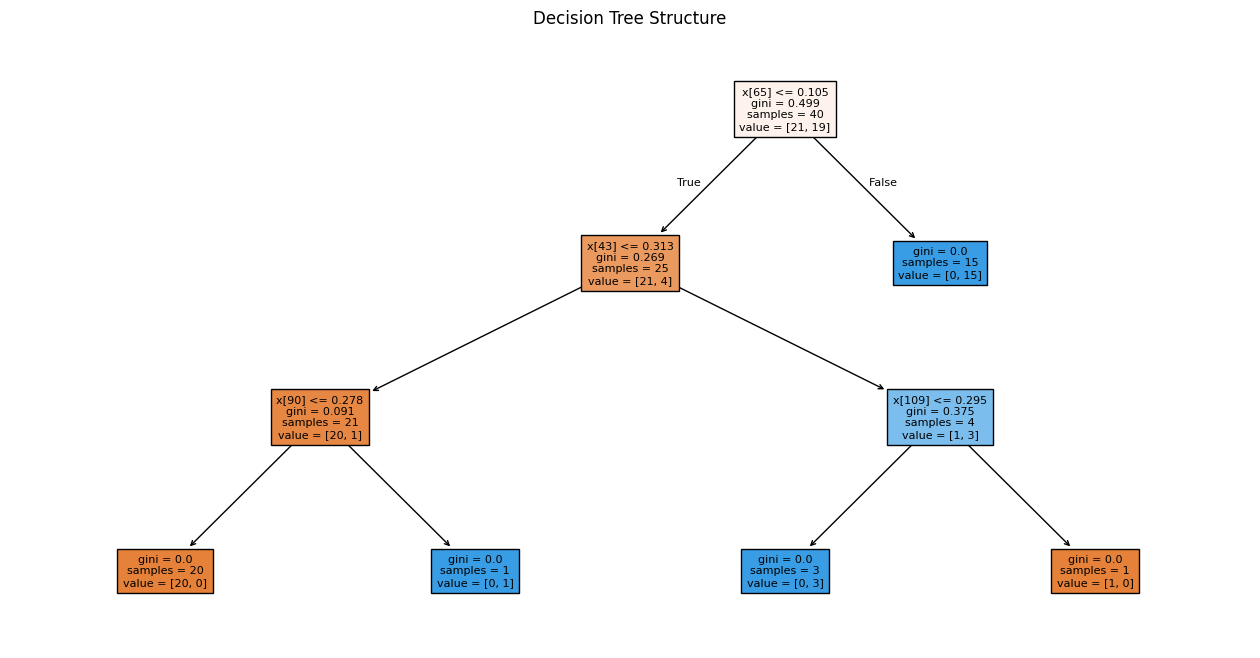

In [16]:
plt.figure(figsize=(16,8))

plot_tree(
    decision_tree_model,
    filled=True,
    fontsize=8
)

plt.title("Decision Tree Structure")
plt.show()

### **Graphical Analysis and Model Interpretation**

The confusion matrix graph illustrates the predictive performance of the Decision Tree model by comparing the actual class labels with the predicted labels. The diagonal values represent correct classification, while the off-diagonal values indicate misclasstifications.
<br><br>
A higher concentration of values along the main diagonal suggests that the model was able to distinguish effectively between high-risk and low-risk symptom descriptions. In the context of clinical triage, this analysis is particularly important, as false negatives in high-risk cases may lead to critical decision errors.
<br><br>
The decision tree structure graph provides a visual representation of how the model makes decision based on the TF-IDF numerical features. Each branch corresponds to a sequence of decision rules derived from the textual symptom patterns identified durig training.
<br><br>

### **Analytical Discussion**
The Decision Tree model demostranted an interpretable classification structure, allowing visualization of the decision-makin process. Symptoms associated with severe conditions, such as chest pain, shortness of breath, and loss of consciousness, tend to contribute significanty to the classification of the high-risk category.
<br><br>
However, due to the the limited size of the dataset, the model may present overfitting tendencies, especially when learning highly specific textual patterns. This behavior should be further compared with the Logistic Regression model in the subsequent stage of the study.


### **Logistic Regression Model for Text Classification**

In this stage, a Logistic Regresson model is implemented to perform the same classification task of predicting clinical risk levels based on textual symptom description. Unlike the Decision Treen model, which relies on hieararchical decision rules, Logistic Regression is a linear model taht estimates the probability of each class based on the weighted contribution of input features.
<br><br>
This approach is particularly effective for text classification tasks when combined with TD-IDF vectorization, as it can efficiently handle high-dimensional sparse data. The objective of this step is to train the model, evaluate is performance, and observe its behavior in comparison to the previously implemented Decision Tree model.

In [17]:
# Import Logistic Regression
from sklearn.linear_model import LogisticRegression

# Create model
logistic_model = LogisticRegression()

# Train model
logistic_model.fit(x_train, y_train)

# Prediction
y_pred_logistic = logistic_model.predict(x_test)

In [18]:
# Accuracy
accuracy_logistic = accuracy_score(y_test, y_pred_logistic)

print("Logistic Regression Accuracy:", accuracy_logistic)

# Classification report
print("\nClassifcation Report:\n")
print(classification_report(y_test, y_pred_logistic))

Logistic Regression Accuracy: 0.9

Classifcation Report:

              precision    recall  f1-score   support

  alto risco       0.80      1.00      0.89         4
 baixo risco       1.00      0.83      0.91         6

    accuracy                           0.90        10
   macro avg       0.90      0.92      0.90        10
weighted avg       0.92      0.90      0.90        10



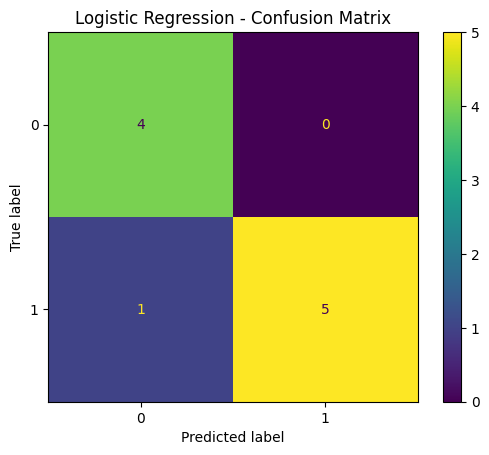

In [19]:
# Confusion matrix
cm_logistic = confusion_matrix(y_test, y_pred_logistic)

# Plot
disp = ConfusionMatrixDisplay(confusion_matrix=cm_logistic)
disp.plot()

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

### **Graphical Analysis of Logistic Regression**

The confusion matrix provides a visual representation of the Logistic Regression mode'l performance by comparing predicted and actual classifications. Corret predictions are displayed along the diagonal, while incorrect pedictions appear in the off-diagonal positions.
<br><br>
Due to its probabilistic nature, Logistic Regression tend to produce more stable and generalized prections, especially when dealing with sparse textual data. This behavior may result in fewer extreme misclassficicatios comprared to more complex models.

<br><br>

### **Preliminary Comparison Between Models**

A preliminary comparison between the Decision Tree and Logistic Regression models reveals important conceptual diferrences. The Decision Tree model operates by creating a sequence of potentially sensitive to variations in the dataset.
<br><br>
On the other hand, Logistic Regression is a linear model that estimates class probabilities based on feature weights. This approach generally provides better generalization when working with high-dimensional text data, such as TF-IDF representations.
<br><br>
At this stage, no detailed comparative analysis is performed; however, these structural differences may influence the model's permormance and will be futher explored in subsequent steps.

### **Naive Bayes Model for Text Classification**

In this stage, the Naive Bayes classifier is imlemented as the third machine learning model for clinical risk classification. This algorithm is widely used in Natural Language Processing tasks due to its efficiency in handliing high-dimensional sparse data, such as TF-IDF representations.
<br><br>
Naive Bayes is based on probabilistic principles and assumes independece between features, which simplifies the computation while still providing strong performance in text classification problems. The objetictive is to its effectiveness and compare it with the previously implemented models.

In [20]:
# Import library Naive Bayes
from sklearn.naive_bayes import MultinomialNB

# Create model
naive_model = MultinomialNB()

# Train
naive_model.fit(x_train, y_train)

# Predict
y_pred_naive = naive_model.predict(x_test)

In [21]:
# Accuracy
accuracy_naive = accuracy_score(y_test, y_pred_naive)

print("Naive Bayes Accuracy:", accuracy_naive)

# Report
print("\nClassification Report:\n")
print(classification_report(y_test, y_pred_naive))

Naive Bayes Accuracy: 1.0

Classification Report:

              precision    recall  f1-score   support

  alto risco       1.00      1.00      1.00         4
 baixo risco       1.00      1.00      1.00         6

    accuracy                           1.00        10
   macro avg       1.00      1.00      1.00        10
weighted avg       1.00      1.00      1.00        10



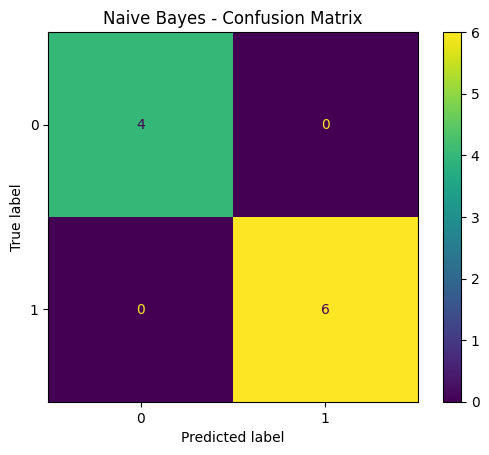

In [22]:
cm_naive = confusion_matrix(y_test, y_pred_naive)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_naive)
disp.plot()

plt.title("Naive Bayes - Confusion Matrix")
plt.show()

                 Model  Accuracy
0        Decision Tree       0.9
1  Logistic Regression       0.9
2          Naive Bayes       1.0


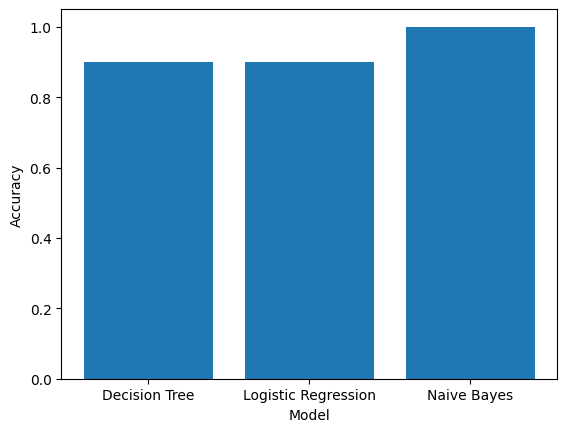

In [23]:
models = ["Decision Tree", "Logistic Regression", "Naive Bayes"]
accuracies = [accuracy_tree, accuracy_logistic, accuracy_naive]

df_results = pd.DataFrame({
    "Model": models,
    "Accuracy": accuracies
})

print(df_results)

# Plot
plt.figure()
plt.bar(df_results["Model"], df_results["Accuracy"])
plt.xlabel("Model")
plt.ylabel("Accuracy")
plt.show()

### **Comparative Analysis of Models**

<br>

| Model               | Characteristics                                   | Strengths                               | Limitations                           |
| ------------------- | ------------------------------------------------- | --------------------------------------- | ------------------------------------- |
| Decision Tree       | Rule-based hierarchical model                     | Easy to interpret                       | Prone to overfitting                  |
| Logistic Regression | Linear probabilistic model                        | Good generalization, stable performance | Limited in capturing complex patterns |
| Naive Bayes         | Probabilistic model based on feature independence | Fast and highly efficient for text data | Assumes independence between features |

<br>

The graphical comparison of accuracy highlights differences in predictive performance across the models. While all models are capable of performing the classification task, their internal structures and learning mechanisms lead to variations in generalization and robustness.


### **Graphical Comparison and Interpretation**

The bar chart comparing model accuracy provides a clear overview of the performance differences among the three algorithms. Each model processes the same TF-IDF input data but applies distinct learning strategies.
<br><br>
The Decision Tree model tends to adapt strongly to the training data, which may result in overfitting. Logistic Regression, by contrast, provides a more stable decision boundary, leading to consistent results. Naive Bayes, despite its simplifying assumptions, often performs efficiently in text classification due to its probabilistic nature.
<br><br>
The confusion matrices further complement this analysis by revealing how each model handles misclassification between high-risk and low-risk categories. This is particularly important in clinical applications, where minimizing false negatives is critical.

<br>

### **Final Considerations**

This study demonstrated the implementation and evaluation of three machine learning models—Decision Tree, Logistic Regression, and Naive Bayes—for the classification of clinical risk based on textual symptom descriptions. Each model presented distinct characteristics in terms of learning strategy, interpretability, and generalization capability.

Logistic Regression and Naive Bayes showed strong performance when combined with TF-IDF, reinforcing their suitability for Natural Language Processing tasks. The Decision Tree model, although highly interpretable, may require additional tuning to avoid overfitting.

From an application perspective, such models can be integrated into real-world clinical triage systems, supporting decision-making processes and prioritizing patient care. Improvements could include expanding the dataset, applying text preprocessing techniques (such as stemming and stopword removal), and exploring more advanced models like neural networks.

This project was developed as part of the second phase of the academic program at FIAP, with the objective of consolidating practical knowledge in the field of Artificial Intelligence. The activity contributed to a deeper understanding of text representation, supervised learning algorithms, and model evaluation techniques within the context of the Artificial Intelligence Technology degree program.

